# Eksperimen P1.9: Nested Stratified K-Fold Cross-Validation & Realistic Deployment Imputation
## Protokol Evaluasi Rigor Tanpa Data Leakage (Menjawab Kritik Reviewer A & B)

Penelitian ini merombak protokol evaluasi untuk membuktikan validitas metodologis secara tuntas:
1. **Nested Stratified 5-Fold Cross-Validation (Menjawab Kritik 1 - Reviewer B):**
   - **Outer Loop:** 5-Fold Stratified K-Fold pada seluruh dataset (10.127 baris) untuk memisahkan `outer_train` (~8.101 baris) dan `outer_val` (~2.026 baris).
   - **Zero Leakage:** Pra-pemrosesan (encoding kategorikal, z-score scaling), penentuan mask missingness, fitness GA, dan tuning downstream dilakukan **HANYA** di dalam `outer_train`.
   - **Inner Loop:** 3-Fold Stratified K-Fold di dalam `outer_train` untuk evaluasi fitness GA dan hyperparameter tuning.
2. **Realisme Deployment / Incomplete Validation Set (Menjawab Kritik 2 - Reviewer B):**
   - `outer_val` diuji dalam dua skenario: **Clean (0% missing)** sebagai kontrol dan **Incomplete (15%-90% missing)** untuk mensimulasikan deployment di masa depan.
   - **Mekanisme Induktif GA:** GA bersifat transduktif pada data latih; untuk data baru (`outer_val`), representasi optimal GA dijadikan peta referensi dengan melatih `KNNImputer(k=5)` pada matriks hasil optimasi GA, lalu mengimputasi `outer_val` tanpa menyentuh label $y$.
3. **Pelaporan Statistik Terbuka:**
   - Unit pairing: Outer Fold × Random Seed ($N=25, df=24$).
   - Menyertakan **Mean** dan **Median** sebagai *primary benchmarks*.


In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.experimental import enable_halving_search_cv, enable_iterative_imputer
from sklearn.model_selection import HalvingRandomSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, mean_squared_error
)
from sklearn.pipeline import Pipeline
from scipy.stats import ttest_rel, spearmanr

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import matplotlib.pyplot as plt
import seaborn as sns

RNG_SEED = 42
np.random.seed(RNG_SEED)


In [2]:
# 1. Load Dataset Bank Churners
df = pd.read_csv("data/BankChurners.csv")

# 2. Drop kolom identitas dan Naive Bayes bawaan
df = df.drop(columns=[
    "CLIENTNUM",
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1",
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2"
])

# 3. Encode Target Variable (Attrition_Flag)
df["Attrition_Flag"] = df["Attrition_Flag"].map({
    "Existing Customer": 0,
    "Attrited Customer": 1
})

# 4. Definisikan Kolom Kategorial dan Kontinu
categorical_cols = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]
continuous_cols = [col for col in df.columns if col not in categorical_cols + ["Attrition_Flag"]]

X_all = df.drop(columns=["Attrition_Flag"])
y_all = df["Attrition_Flag"]
all_features = X_all.columns.tolist()

print(f"Dataset Shape: {df.shape}")
print(f"Distribusi Target: {np.bincount(y_all)} ({np.mean(y_all)*100:.2f}% Positive Churn)")
print(f"Fitur Kontinu ({len(continuous_cols)}): {continuous_cols}")
print(f"Fitur Kategorial ({len(categorical_cols)}): {categorical_cols}")


Dataset Shape: (10127, 20)
Distribusi Target: [8500 1627] (16.07% Positive Churn)
Fitur Kontinu (14): ['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
Fitur Kategorial (5): ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']


In [3]:
def introduce_mcar_missing(data, missing_rate=0.10, columns=None, random_state=42):
    """Apply constrained MCAR masking while keeping every row/column usable."""
    if not 0.0 <= missing_rate < 1.0:
        raise ValueError("missing_rate must be in [0, 1).")

    columns = list(data.columns if columns is None else columns)
    rng = np.random.RandomState(random_state)
    n_rows = len(data)
    n_cols = len(columns)
    mask = np.zeros((n_rows, n_cols), dtype=bool)

    max_feasible_rate = 1.0 - (1.0 / n_cols)
    if missing_rate > max_feasible_rate:
        mask[:, :] = True
        observed_cols = np.resize(rng.permutation(n_cols), n_rows)
        mask[np.arange(n_rows), observed_cols] = False
    else:
        n_missing = min(int(n_rows * missing_rate), max(0, n_rows - 1))
        for col_pos in range(n_cols):
            selected = rng.choice(n_rows, size=n_missing, replace=False)
            mask[selected, col_pos] = True

        all_missing_rows = np.flatnonzero(mask.all(axis=1))
        for row_pos in all_missing_rows:
            col_pos = int(rng.choice(np.flatnonzero(mask[row_pos])))
            mask[row_pos, col_pos] = False

    for col_pos in range(n_cols):
        if mask[:, col_pos].all():
            candidates = np.flatnonzero(mask.sum(axis=1) >= 2)
            if len(candidates):
                mask[int(rng.choice(candidates)), col_pos] = False
            else:
                mask[int(rng.randint(0, n_rows)), col_pos] = False

    data_missing = data.copy()
    data_missing_values = data_missing[columns].values.astype(float)
    data_missing_values[mask] = np.nan
    data_missing[columns] = data_missing_values

    missing_mask_df = pd.DataFrame(mask, columns=columns, index=data.index)
    original_values = {col: data.loc[missing_mask_df[col], col].copy() for col in columns}
    return data_missing, missing_mask_df, original_values


def calculate_imputation_metrics(original_values, missing_mask, imputed_data, continuous_cols, categorical_cols):
    rmse_scores = []
    pfc_scores = []
    for col in original_values.keys():
        true_val = original_values[col]
        pred_val = imputed_data.loc[missing_mask[col], col]
        if len(true_val) == 0:
            continue
        if col in continuous_cols:
            rmse = np.sqrt(mean_squared_error(true_val, pred_val))
            rmse_scores.append(rmse)
        elif col in categorical_cols:
            pred_round = pred_val.round().astype(int)
            pfc = np.mean(true_val != pred_round)
            pfc_scores.append(pfc)
            
    mean_rmse = float(np.mean(rmse_scores)) if len(rmse_scores) > 0 else 0.0
    mean_pfc = float(np.mean(pfc_scores)) if len(pfc_scores) > 0 else 0.0
    return mean_rmse, mean_pfc


In [4]:
class BaselineImputer:
    """Baseline Imputer Wrapper with distinct fit_transform (outer_train) and transform (outer_val)."""
    def __init__(self, method="Mean", categorical_cols=None, random_state=42):
        self.method = method
        self.categorical_cols = categorical_cols or []
        self.random_state = random_state
        self.imputer = None
        self.col_limits = {}

    def fit_transform(self, X_train_missing):
        for col in self.categorical_cols:
            obs = X_train_missing[col].dropna()
            self.col_limits[col] = (obs.min(), obs.max())

        if self.method == "Mean":
            self.imputer = SimpleImputer(strategy="mean")
        elif self.method == "Median":
            self.imputer = SimpleImputer(strategy="median")
        elif self.method == "KNN":
            self.imputer = KNNImputer(n_neighbors=5)
        elif self.method == "MICE":
            self.imputer = IterativeImputer(random_state=self.random_state, max_iter=10)
        elif self.method == "MissForest":
            self.imputer = IterativeImputer(
                estimator=RandomForestRegressor(n_estimators=10, max_depth=6, random_state=self.random_state, n_jobs=-1),
                random_state=self.random_state,
                max_iter=5
            )
        else:
            raise ValueError(f"Method '{self.method}' is not supported.")

        imputed_vals = self.imputer.fit_transform(X_train_missing)
        imputed_df = pd.DataFrame(imputed_vals, columns=X_train_missing.columns, index=X_train_missing.index)
        for col in self.categorical_cols:
            if col in imputed_df.columns:
                min_v, max_v = self.col_limits[col]
                imputed_df[col] = imputed_df[col].round().clip(lower=min_v, upper=max_v).astype(int)
        return imputed_df

    def transform(self, X_test_missing):
        imputed_vals = self.imputer.transform(X_test_missing)
        imputed_df = pd.DataFrame(imputed_vals, columns=X_test_missing.columns, index=X_test_missing.index)
        for col in self.categorical_cols:
            if col in imputed_df.columns:
                min_v, max_v = self.col_limits[col]
                imputed_df[col] = imputed_df[col].round().clip(lower=min_v, upper=max_v).astype(int)
        return imputed_df


In [ ]:
class GAImputer:
    """
    Transductive Genetic Algorithm Imputer for Training Data +
    Inductive KNN-Map Imputer for Deployment Validation Data.
    """
    def __init__(self, pop_size=15, generations=15, mutation_rate=0.2, crossover_rate=0.8,
                 early_stopping_patience=3, fitness_subset_size=3000, random_state=42):
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.crossover_rate = crossover_rate
        self.early_stopping_patience = early_stopping_patience
        self.fitness_subset_size = fitness_subset_size
        self.random_state = random_state
        self.rng = np.random.RandomState(random_state)
        self.inductive_imputer = None
        self.col_limits = {}
        
    def fit_transform(self, X_missing, y_train, baseline_imputations=None, categorical_cols=None):
        missing_rows, missing_cols = np.where(X_missing.isna())
        missing_coords = list(zip(missing_rows, missing_cols))
        categorical_cols = categorical_cols or []
        for col in categorical_cols:
            obs = X_missing[col].dropna()
            self.col_limits[col] = (obs.min(), obs.max())

        if len(missing_coords) == 0:
            return X_missing.copy(), []
            
        col_stats = {}
        for col_idx, col_name in enumerate(X_missing.columns):
            observed = X_missing[col_name].dropna()
            col_stats[col_idx] = {
                "mean": observed.mean(),
                "std": observed.std() if observed.std() > 0 else 1.0,
                "min": observed.min(),
                "max": observed.max()
            }
            
        gene_means = np.array([col_stats[c_idx]["mean"] for c_idx in missing_cols])
        gene_stds = np.array([col_stats[c_idx]["std"] for c_idx in missing_cols])
        gene_mins = np.array([col_stats[c_idx]["min"] for c_idx in missing_cols])
        gene_maxs = np.array([col_stats[c_idx]["max"] for c_idx in missing_cols])
        
        # Inner CV subset strictly inside outer_train
        if len(X_missing) > self.fitness_subset_size:
            X_sub, _, y_sub, _ = train_test_split(
                X_missing, y_train, train_size=self.fitness_subset_size,
                stratify=y_train, random_state=self.random_state
            )
            sub_indices = X_sub.index
            y_eval_final = y_sub
        else:
            sub_indices = X_missing.index
            y_eval_final = y_train
            
        def create_chromosome():
            return np.clip(self.rng.normal(gene_means, gene_stds), gene_mins, gene_maxs)
            
        X_missing_values = X_missing.values.copy()
        def evaluate_fitness(chromosome):
            X_filled_vals = X_missing_values.copy()
            X_filled_vals[missing_rows, missing_cols] = chromosome
            X_filled_df = pd.DataFrame(X_filled_vals, columns=X_missing.columns, index=X_missing.index)
            for col in categorical_cols:
                if col in X_filled_df.columns:
                    X_filled_df[col] = X_filled_df[col].round().astype(int)
            X_eval = X_filled_df.loc[sub_indices]
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('rf', RandomForestClassifier(n_estimators=50, max_depth=6, random_state=self.random_state, n_jobs=-1))
            ])
            scores = cross_val_score(pipeline, X_eval, y_eval_final, cv=3, scoring="roc_auc", n_jobs=-1)
            return scores.mean()
            
        population = []
        if baseline_imputations is not None:
            for name, X_base in baseline_imputations.items():
                c = X_base.values[missing_rows, missing_cols].copy()
                population.append(c)
                
        while len(population) < self.pop_size:
            population.append(create_chromosome())
            
        fitness_scores = [evaluate_fitness(ind) for ind in population]
        best_fitness_history = []
        best_fitness = -1
        best_chromosome = None
        no_improvement_count = 0
        
        for gen in range(self.generations):
            best_idx = int(np.argmax(fitness_scores))
            current_best_fitness = fitness_scores[best_idx]
            best_fitness_history.append(current_best_fitness)
            
            if current_best_fitness > best_fitness:
                best_fitness = current_best_fitness
                best_chromosome = population[best_idx].copy()
                no_improvement_count = 0
            else:
                no_improvement_count += 1
                
            if no_improvement_count >= self.early_stopping_patience:
                break
                
            def tournament_select():
                i, j = self.rng.randint(0, self.pop_size, size=2)
                return population[i] if fitness_scores[i] > fitness_scores[j] else population[j]
                
            new_population = [best_chromosome.copy()]
            while len(new_population) < self.pop_size:
                p1 = tournament_select()
                p2 = tournament_select()
                if self.rng.rand() < self.crossover_rate:
                    mask = self.rng.rand(len(missing_coords)) < 0.5
                    child = np.where(mask, p1, p2)
                else:
                    child = p1.copy()
                    
                mutation_mask = self.rng.rand(len(missing_coords)) < self.mutation_rate
                if np.any(mutation_mask):
                    child[mutation_mask] += self.rng.normal(0, gene_stds[mutation_mask] * 0.1)
                    child = np.clip(child, gene_mins, gene_maxs)
                new_population.append(child)
                
            population = new_population
            fitness_scores = [evaluate_fitness(ind) for ind in population]
            
        final_best_idx = int(np.argmax(fitness_scores))
        if fitness_scores[final_best_idx] > best_fitness:
            best_chromosome = population[final_best_idx]
            
        X_imputed_vals = X_missing_values.copy()
        X_imputed_vals[missing_rows, missing_cols] = best_chromosome
        X_imputed = pd.DataFrame(X_imputed_vals, columns=X_missing.columns, index=X_missing.index)
        for col in categorical_cols:
            if col in X_imputed.columns:
                min_v, max_v = self.col_limits[col]
                X_imputed[col] = X_imputed[col].round().clip(lower=min_v, upper=max_v).astype(int)

        # FIT INDUCTIVE IMPUTER PADA X_train_imputed_GA
        self.inductive_imputer = KNNImputer(n_neighbors=5)
        self.inductive_imputer.fit(X_imputed)

        return X_imputed, best_fitness_history

    def transform(self, X_val_missing):
        imputed_vals = self.inductive_imputer.transform(X_val_missing)
        imputed_df = pd.DataFrame(imputed_vals, columns=X_val_missing.columns, index=X_val_missing.index)
        for col, (min_v, max_v) in self.col_limits.items():
            if col in imputed_df.columns:
                imputed_df[col] = imputed_df[col].round().clip(lower=min_v, upper=max_v).astype(int)
        return imputed_df


class GAKNNImputer(GAImputer):
    def __init__(self, *args, task="classification", **kwargs):
        super().__init__(*args, **kwargs)
        self.task = task

    def fit_transform(self, X_missing, y_train, baseline_imputations=None, categorical_cols=None):
        missing_rows, missing_cols = np.where(X_missing.isna())
        missing_coords = list(zip(missing_rows, missing_cols))
        categorical_cols = categorical_cols or []
        for col in categorical_cols:
            obs = X_missing[col].dropna()
            self.col_limits[col] = (obs.min(), obs.max())

        if len(missing_coords) == 0:
            return X_missing.copy(), []

        col_stats = {}
        for col_idx, col_name in enumerate(X_missing.columns):
            observed = X_missing[col_name].dropna()
            col_stats[col_idx] = {
                "mean": observed.mean(),
                "std": observed.std() if observed.std() > 0 else 1.0,
                "min": observed.min(),
                "max": observed.max(),
            }

        gene_stds = np.array([col_stats[c_idx]["std"] for c_idx in missing_cols])
        gene_mins = np.array([col_stats[c_idx]["min"] for c_idx in missing_cols])
        gene_maxs = np.array([col_stats[c_idx]["max"] for c_idx in missing_cols])

        if len(X_missing) > self.fitness_subset_size:
            X_sub, _, y_sub, _ = train_test_split(
                X_missing, y_train, train_size=self.fitness_subset_size, random_state=self.random_state, stratify=y_train
            )
            sub_indices = X_sub.index
            y_eval_final = y_sub
        else:
            sub_indices = X_missing.index
            y_eval_final = y_train

        categorical_positions = {}
        for col in categorical_cols:
            if col in X_missing.columns:
                col_idx = X_missing.columns.get_loc(col)
                observed_categories = np.sort(X_missing[col].dropna().unique().astype(float))
                if len(observed_categories):
                    categorical_positions[col_idx] = observed_categories

        knn_chromosome = baseline_imputations["KNN"].values[missing_rows, missing_cols].astype(float)

        def repair_chromosome(chromosome):
            values = np.asarray(chromosome, dtype=float).copy()
            values = np.clip(values, gene_mins, gene_maxs)
            for gene_pos, col_idx in enumerate(missing_cols):
                if col_idx in categorical_positions:
                    categories = categorical_positions[col_idx]
                    values[gene_pos] = categories[np.argmin(np.abs(categories - values[gene_pos]))]
            return values

        knn_chromosome = repair_chromosome(knn_chromosome)
        X_missing_values = X_missing.values.copy()

        def evaluate_fitness(chromosome):
            chromosome = repair_chromosome(chromosome)
            X_filled_vals = X_missing_values.copy()
            X_filled_vals[missing_rows, missing_cols] = chromosome
            X_filled_df = pd.DataFrame(X_filled_vals, columns=X_missing.columns, index=X_missing.index)
            X_eval = X_filled_df.loc[sub_indices]
            pipeline = Pipeline([("scaler", StandardScaler()), ("rf", RandomForestClassifier(n_estimators=50, max_depth=6, random_state=self.random_state, n_jobs=-1))])
            scores = cross_val_score(pipeline, X_eval, y_eval_final, cv=3, scoring="roc_auc", n_jobs=-1)
            return scores.mean()

        population = [knn_chromosome.copy()]
        for name, X_base in (baseline_imputations or {}).items():
            if name == "KNN":
                continue
            population.append(repair_chromosome(X_base.values[missing_rows, missing_cols]))
            if len(population) >= self.pop_size:
                break

        while len(population) < self.pop_size:
            candidate = knn_chromosome + self.rng.normal(0, gene_stds * 0.1)
            population.append(repair_chromosome(candidate))

        fitness_scores = [evaluate_fitness(ind) for ind in population]
        best_fitness_history = []
        best_fitness = -np.inf
        best_chromosome = knn_chromosome.copy()
        no_improvement_count = 0

        for _ in range(self.generations):
            best_idx = int(np.argmax(fitness_scores))
            current_best_fitness = fitness_scores[best_idx]
            best_fitness_history.append(current_best_fitness)

            if current_best_fitness > best_fitness:
                best_fitness = current_best_fitness
                best_chromosome = population[best_idx].copy()
                no_improvement_count = 0
            else:
                no_improvement_count += 1

            if no_improvement_count >= self.early_stopping_patience:
                break

            def tournament_select():
                i, j = self.rng.randint(0, len(population), size=2)
                return population[i] if fitness_scores[i] > fitness_scores[j] else population[j]

            new_population = [best_chromosome.copy()]
            if len(new_population) < self.pop_size:
                new_population.append(knn_chromosome.copy())

            while len(new_population) < self.pop_size:
                p1 = tournament_select()
                p2 = tournament_select()
                if self.rng.rand() < self.crossover_rate:
                    crossover_mask = self.rng.rand(len(missing_coords)) < 0.5
                    child = np.where(crossover_mask, p1, p2)
                else:
                    child = p1.copy()

                mutation_mask = self.rng.rand(len(missing_coords)) < self.mutation_rate
                for gene_pos in np.flatnonzero(mutation_mask):
                    col_idx = missing_cols[gene_pos]
                    if col_idx in categorical_positions:
                        categories = categorical_positions[col_idx]
                        if self.rng.rand() < 0.7:
                            child[gene_pos] = knn_chromosome[gene_pos]
                        else:
                            child[gene_pos] = self.rng.choice(categories)
                    else:
                        child[gene_pos] = knn_chromosome[gene_pos] + self.rng.normal(0, gene_stds[gene_pos] * 0.1)
                new_population.append(repair_chromosome(child))

            population = new_population
            fitness_scores = [evaluate_fitness(ind) for ind in population]

        final_best_idx = int(np.argmax(fitness_scores))
        if fitness_scores[final_best_idx] > best_fitness:
            best_chromosome = population[final_best_idx].copy()

        X_imputed_vals = X_missing_values.copy()
        X_imputed_vals[missing_rows, missing_cols] = repair_chromosome(best_chromosome)
        X_imputed = pd.DataFrame(X_imputed_vals, columns=X_missing.columns, index=X_missing.index)
        for col in categorical_cols:
            if col in X_imputed.columns:
                min_v, max_v = self.col_limits[col]
                X_imputed[col] = X_imputed[col].round().clip(lower=min_v, upper=max_v).astype(int)

        # FIT INDUCTIVE IMPUTER PADA X_train_imputed_GAKNN
        self.inductive_imputer = KNNImputer(n_neighbors=5)
        self.inductive_imputer.fit(X_imputed)

        return X_imputed, best_fitness_history


In [6]:
def tune_rf_optuna(X_train_scaled, y_train, n_trials=20, cv=3, random_state=42):
    cv_split = StratifiedKFold(n_splits=cv, shuffle=True, random_state=random_state)
    def objective(trial):
        params = {
            'n_estimators': trial.suggest_categorical('n_estimators', [100, 200, 300]),
            'max_depth': trial.suggest_int('max_depth', 4, 12),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample', None]),
            'random_state': random_state,
            'n_jobs': -1
        }
        clf = RandomForestClassifier(**params)
        scores = cross_val_score(clf, X_train_scaled, y_train, cv=cv_split, scoring='roc_auc', n_jobs=-1)
        return scores.mean()

    sampler = optuna.samplers.TPESampler(seed=random_state)
    study = optuna.create_study(direction='maximize', sampler=sampler)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    best_params = study.best_params
    best_params['random_state'] = random_state
    best_params['n_jobs'] = -1
    best_clf = RandomForestClassifier(**best_params)
    best_clf.fit(X_train_scaled, y_train)
    return best_clf, best_params


def tune_rf_random_search(X_train_scaled, y_train, n_iter=20, cv=3, random_state=42):
    cv_split = StratifiedKFold(n_splits=cv, shuffle=True, random_state=random_state)
    param_dist = {
        'n_estimators': [100, 200, 300],
        'max_depth': [4, 6, 8, 10, 12, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', 0.5],
        'class_weight': ['balanced', 'balanced_subsample', None]
    }
    base_rf = RandomForestClassifier(random_state=random_state, n_jobs=-1)
    search = RandomizedSearchCV(
        estimator=base_rf,
        param_distributions=param_dist,
        n_iter=n_iter,
        cv=cv_split,
        scoring='roc_auc',
        random_state=random_state,
        n_jobs=-1
    )
    search.fit(X_train_scaled, y_train)
    return search.best_estimator_, search.best_params_


def tune_rf_halving_search(X_train_scaled, y_train, cv=3, random_state=42):
    cv_split = StratifiedKFold(n_splits=cv, shuffle=True, random_state=random_state)
    param_dist = {
        'n_estimators': [100, 200, 300],
        'max_depth': [4, 6, 8, 10, 12, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', 0.5],
        'class_weight': ['balanced', 'balanced_subsample', None]
    }
    base_rf = RandomForestClassifier(random_state=random_state, n_jobs=-1)
    search = HalvingRandomSearchCV(
        estimator=base_rf,
        param_distributions=param_dist,
        factor=3,
        min_resources=500,
        cv=cv_split,
        scoring='roc_auc',
        random_state=random_state,
        n_jobs=-1
    )
    search.fit(X_train_scaled, y_train)
    return search.best_estimator_, search.best_params_


def evaluate_downstream_model(X_train_filled, y_train, X_val_imputed, y_val, tuning_method=None, random_state=42):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_filled)
    X_val_scaled = scaler.transform(X_val_imputed)
    
    best_params = None
    if tuning_method == 'optuna':
        clf, best_params = tune_rf_optuna(X_train_scaled, y_train, n_trials=20, cv=3, random_state=random_state)
    elif tuning_method == 'random_search':
        clf, best_params = tune_rf_random_search(X_train_scaled, y_train, n_iter=20, cv=3, random_state=random_state)
    elif tuning_method == 'halving_search':
        clf, best_params = tune_rf_halving_search(X_train_scaled, y_train, cv=3, random_state=random_state)
    else:
        clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=random_state, n_jobs=-1)
        clf.fit(X_train_scaled, y_train)
    
    y_pred = clf.predict(X_val_scaled)
    y_proba = clf.predict_proba(X_val_scaled)[:, 1]
    
    metrics = {
        "Accuracy": float(accuracy_score(y_val, y_pred)),
        "Precision": float(precision_score(y_val, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_val, y_pred, zero_division=0)),
        "F1": float(f1_score(y_val, y_pred, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_val, y_proba))
    }
    if best_params is not None:
        metrics["Best_Params"] = best_params
    return metrics


In [7]:
# ==============================================================================
# KONFIGURASI SKENARIO EKSPERIMEN NESTED CV (P1.9)
# ==============================================================================
N_OUTER_FOLDS = 5
MISSING_RATES = [0.15, 0.30, 0.45, 0.60, 0.75, 0.90]
HIGH_SPARSITY_RATES = [0.60, 0.75, 0.90]
METHODS = ["Mean", "Median", "KNN", "MICE", "MissForest", "GA-based", "GA-KNN"]
TUNING_METHODS = [
    ("Default_RF", None),
    ("Optuna", "optuna"),
    ("RandomSearch", "random_search"),
    ("HalvingSearch", "halving_search"),
]
SEEDS = [42, 101, 202, 303, 404]

RESULTS_CSV_OUTPUT = "ga_nested_cv_results_p1_9.csv"
PAIRWISE_STATS_OUTPUT = "pairwise_nested_cv_stats_p1_9.csv"
SUMMARY_MEAN_OUTPUT = "ga_nested_cv_summary_mean_p1_9.csv"
SUMMARY_STD_OUTPUT = "ga_nested_cv_summary_std_p1_9.csv"

print(f"Total Outer Folds   : {N_OUTER_FOLDS}")
print(f"Total Missing Rates : {len(MISSING_RATES)} {MISSING_RATES}")
print(f"Total Seeds         : {len(SEEDS)} {SEEDS}")
print(f"Total Methods       : {len(METHODS)} {METHODS}")
print(f"Total Tuning Regimes: {len(TUNING_METHODS)} {[t[0] for t in TUNING_METHODS]}")
print(f"Total Scenarios     : {N_OUTER_FOLDS} folds × {len(MISSING_RATES)} rates × {len(SEEDS)} seeds = {N_OUTER_FOLDS * len(MISSING_RATES) * len(SEEDS)} scenarios")
print(f"Total Evaluations   : {N_OUTER_FOLDS * len(MISSING_RATES) * len(SEEDS) * len(METHODS) * len(TUNING_METHODS)} model evaluations")


Total Outer Folds   : 5
Total Missing Rates : 6 [0.15, 0.3, 0.45, 0.6, 0.75, 0.9]
Total Seeds         : 5 [42, 101, 202, 303, 404]
Total Methods       : 7 ['Mean', 'Median', 'KNN', 'MICE', 'MissForest', 'GA-based', 'GA-KNN']
Total Tuning Regimes: 4 ['Default_RF', 'Optuna', 'RandomSearch', 'HalvingSearch']
Total Scenarios     : 5 folds × 6 rates × 5 seeds = 150 scenarios
Total Evaluations   : 4200 model evaluations


In [8]:
# Inisialisasi Outer 5-Fold Stratified Split
skf_outer = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=RNG_SEED)
outer_splits = list(skf_outer.split(X_all, y_all))

experiment_results = []
start_total_time = time.time()

# Untuk menjalankan full experiment, iterasikan seluruh outer_folds
# Di sini loop terstruktur rapi dan siap dieksekusi
for fold_idx, (outer_train_idx, outer_val_idx) in enumerate(outer_splits):
    print("\n" + "#" * 80)
    print(f"### OUTER FOLD {fold_idx + 1} / {N_OUTER_FOLDS} ###")
    print("#" * 80)

    # 1. Programmatic assertions: pastikan tidak ada data leakage
    assert set(outer_train_idx).isdisjoint(set(outer_val_idx)), "LEAKAGE ERROR: train dan val bertumpukan!"
    assert len(outer_train_idx) + len(outer_val_idx) == len(df), "INDEX ERROR: jumlah observasi tidak cocok!"

    X_outer_train_raw = X_all.iloc[outer_train_idx].copy().reset_index(drop=True)
    y_outer_train = y_all.iloc[outer_train_idx].copy().reset_index(drop=True)
    X_outer_val_raw = X_all.iloc[outer_val_idx].copy().reset_index(drop=True)
    y_outer_val = y_all.iloc[outer_val_idx].copy().reset_index(drop=True)

    # 2. Categorical encoding строго di-fit hanya pada outer_train
    X_tr_enc = X_outer_train_raw.copy()
    X_val_enc = X_outer_val_raw.copy()
    for col in categorical_cols:
        train_cats = sorted(X_outer_train_raw[col].dropna().unique())
        cat2idx = {cat: i for i, cat in enumerate(train_cats)}
        mode_idx = cat2idx[X_outer_train_raw[col].mode()[0]]
        X_tr_enc[col] = X_outer_train_raw[col].map(cat2idx).astype(float)
        X_val_enc[col] = X_outer_val_raw[col].map(lambda c: cat2idx.get(c, mode_idx)).astype(float)

    for rate in MISSING_RATES:
        print(f"\n--- Missing Rate: {int(rate * 100)}% (Fold {fold_idx + 1}) ---")
        for seed in SEEDS:
            # Suntikkan missing rate pada outer_train
            X_tr_mis, tr_mask, tr_orig = introduce_mcar_missing(
                X_tr_enc, missing_rate=rate, columns=all_features, random_state=seed
            )
            # Suntikkan missing rate pada outer_val (skenario deployment)
            X_val_mis, val_mask, val_orig = introduce_mcar_missing(
                X_val_enc, missing_rate=rate, columns=all_features, random_state=seed + 999
            )

            actual_tr_rate = float(X_tr_mis.isna().sum().sum() / X_tr_mis.size)
            actual_val_rate = float(X_val_mis.isna().sum().sum() / X_val_mis.size)

            baseline_imputations = {}
            for meth in METHODS:
                t_imp_0 = time.time()
                if meth in ["Mean", "Median", "KNN", "MICE", "MissForest"]:
                    imputer = BaselineImputer(method=meth, categorical_cols=categorical_cols, random_state=seed)
                    X_tr_imp = imputer.fit_transform(X_tr_mis)
                    baseline_imputations[meth] = X_tr_imp
                elif meth == "GA-based":
                    imputer = GAImputer(
                        pop_size=15, generations=15, mutation_rate=0.2, crossover_rate=0.8,
                        early_stopping_patience=3, fitness_subset_size=3000, random_state=seed
                    )
                    X_tr_imp, _ = imputer.fit_transform(
                        X_tr_mis, y_outer_train, baseline_imputations=baseline_imputations, categorical_cols=categorical_cols
                    )
                elif meth == "GA-KNN":
                    imputer = GAKNNImputer(
                        pop_size=15, generations=15, mutation_rate=0.2, crossover_rate=0.8,
                        early_stopping_patience=3, fitness_subset_size=3000, random_state=seed, task="classification"
                    )
                    X_tr_imp, _ = imputer.fit_transform(
                        X_tr_mis, y_outer_train, baseline_imputations=baseline_imputations, categorical_cols=categorical_cols
                    )

                train_impute_runtime = time.time() - t_imp_0

                # Inductive Imputation on outer_val (Incomplete deployment scenario)
                t_infer_0 = time.time()
                X_val_imp = imputer.transform(X_val_mis)
                infer_runtime = time.time() - t_infer_0

                # Assertion: tidak boleh ada residual NaNs
                assert X_tr_imp.isna().sum().sum() == 0, f"Residual NaN in outer_train for {meth}"
                assert X_val_imp.isna().sum().sum() == 0, f"Residual NaN in outer_val for {meth}"

                # Imputation quality metrics
                rmse_tr, pfc_tr = calculate_imputation_metrics(tr_orig, tr_mask, X_tr_imp, continuous_cols, categorical_cols)
                rmse_val, pfc_val = calculate_imputation_metrics(val_orig, val_mask, X_val_imp, continuous_cols, categorical_cols)

                # Evaluasi 4 strategi tuning downstream
                for tuning_name, tuning_key in TUNING_METHODS:
                    t_eval_0 = time.time()
                    
                    # 1. Evaluasi pada outer_val INCOMPLETE (skenario masa depan / deployment nyata)
                    metrics_incomp = evaluate_downstream_model(
                        X_tr_imp, y_outer_train, X_val_imp, y_outer_val, tuning_method=tuning_key, random_state=seed
                    )
                    
                    # 2. Evaluasi pada outer_val CLEAN (baseline kontrol 0% missing)
                    metrics_clean = evaluate_downstream_model(
                        X_tr_imp, y_outer_train, X_val_enc, y_outer_val, tuning_method=tuning_key, random_state=seed
                    )
                    
                    eval_runtime = time.time() - t_eval_0

                    experiment_results.append({
                        "Outer_Fold": fold_idx + 1,
                        "Seed": seed,
                        "Missing_Rate": rate,
                        "Actual_Train_Missing": actual_tr_rate,
                        "Actual_Val_Missing": actual_val_rate,
                        "Imputation_Method": meth,
                        "Tuning_Method": tuning_name,
                        "Train_RMSE": rmse_tr,
                        "Train_PFC": pfc_tr,
                        "Val_RMSE": rmse_val,
                        "Val_PFC": pfc_val,
                        "Clean_Val_Accuracy": metrics_clean["Accuracy"],
                        "Clean_Val_F1": metrics_clean["F1"],
                        "Clean_Val_ROC_AUC": metrics_clean["ROC-AUC"],
                        "Incomp_Val_Accuracy": metrics_incomp["Accuracy"],
                        "Incomp_Val_Precision": metrics_incomp["Precision"],
                        "Incomp_Val_Recall": metrics_incomp["Recall"],
                        "Incomp_Val_F1": metrics_incomp["F1"],
                        "Incomp_Val_ROC_AUC": metrics_incomp["ROC-AUC"],
                        "Train_Impute_Runtime": train_impute_runtime,
                        "Inference_Runtime": infer_runtime,
                        "Evaluation_Runtime": eval_runtime,
                        "Total_Runtime": train_impute_runtime + infer_runtime + eval_runtime
                    })

    # Simpan checkpoint per outer fold
    df_checkpoint = pd.DataFrame(experiment_results)
    df_checkpoint.to_csv(RESULTS_CSV_OUTPUT, index=False)
    print(f"Checkpoint saved: {len(df_checkpoint)} rows saved to {RESULTS_CSV_OUTPUT}")



################################################################################
### OUTER FOLD 1 / 5 ###
################################################################################

--- Missing Rate: 15% (Fold 1) ---

--- Missing Rate: 30% (Fold 1) ---

--- Missing Rate: 45% (Fold 1) ---

--- Missing Rate: 60% (Fold 1) ---

--- Missing Rate: 75% (Fold 1) ---

--- Missing Rate: 90% (Fold 1) ---
Checkpoint saved: 840 rows saved to ga_nested_cv_results_p1_9.csv

################################################################################
### OUTER FOLD 2 / 5 ###
################################################################################

--- Missing Rate: 15% (Fold 2) ---

--- Missing Rate: 30% (Fold 2) ---

--- Missing Rate: 45% (Fold 2) ---

--- Missing Rate: 60% (Fold 2) ---

--- Missing Rate: 75% (Fold 2) ---

--- Missing Rate: 90% (Fold 2) ---


d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Checkpoint saved: 1680 rows saved to ga_nested_cv_results_p1_9.csv

################################################################################
### OUTER FOLD 3 / 5 ###
################################################################################

--- Missing Rate: 15% (Fold 3) ---


d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reache


--- Missing Rate: 30% (Fold 3) ---


d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reache

... (29 outputs left out)

d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(



--- Missing Rate: 90% (Fold 5) ---


d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\skripsi\topic1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Checkpoint saved: 4200 rows saved to ga_nested_cv_results_p1_9.csv


In [9]:
# ==============================================================================
# STATISTICAL HYPOTHESIS TESTING (N=25 PAIRS, df=24)
# ==============================================================================
if 'df_checkpoint' in globals():
    results_df = df_checkpoint
else:
    results_df = pd.read_csv(RESULTS_CSV_OUTPUT)

# Rata-ratakan skor metrik per (Outer_Fold, Seed, Missing_Rate, Imputation_Method)
df_seed_agg = (
    results_df.groupby(["Missing_Rate", "Imputation_Method", "Outer_Fold", "Seed"])["Incomp_Val_ROC_AUC"]
    .mean()
    .reset_index()
)

def paired_ttest_nested(records, method_a, method_b, rate):
    sub = records[np.isclose(records["Missing_Rate"], rate)]
    # Pair by (Outer_Fold, Seed)
    piv = sub.pivot_table(index=["Outer_Fold", "Seed"], columns="Imputation_Method", values="Incomp_Val_ROC_AUC")
    if method_a not in piv.columns or method_b not in piv.columns:
        return None
    a = piv[method_a].to_numpy()
    b = piv[method_b].to_numpy()
    d = a - b
    n = len(d)
    delta_mean = float(np.mean(d))
    if np.std(d, ddof=1) == 0:
        t_stat, p_val = np.nan, np.nan
        decision = "not significant (p ≥ 0.05)"
    else:
        t_stat, p_val = ttest_rel(a, b)
        t_stat, p_val = float(t_stat), float(p_val)
        if p_val < 0.05:
            winning = method_a if delta_mean > 0 else method_b
            decision = f"Significant: {winning} (p < 0.05)"
        else:
            decision = "not significant (p ≥ 0.05)"
    return {
        "Missing Rate": f"{int(rate*100)}%",
        "Comparison": f"{method_a} vs {method_b}",
        "N": n,
        "df": n - 1,
        "Delta": delta_mean,
        "t-stat": t_stat,
        "p-value": p_val,
        "Statistical Decision": decision
    }

stat_pairs = [
    ("GA-KNN", "Mean"),
    ("GA-KNN", "Median"),
    ("GA-KNN", "KNN"),
    ("GA-KNN", "MissForest"),
    ("GA-KNN", "GA-based"),
    ("GA-based", "Mean"),
    ("GA-based", "Median"),
    ("GA-based", "MissForest")
]

stat_rows = []
for rate in HIGH_SPARSITY_RATES:
    for a, b in stat_pairs:
        res = paired_ttest_nested(df_seed_agg, a, b, rate)
        if res:
            stat_rows.append(res)

df_stats = pd.DataFrame(stat_rows)
df_stats.to_csv(PAIRWISE_STATS_OUTPUT, index=False)
print("=== PAIRED T-TEST RESULTS (NESTED CV: N=25, df=24) ===")
print(df_stats.to_string(index=False))


=== PAIRED T-TEST RESULTS (NESTED CV: N=25, df=24) ===
Missing Rate             Comparison  N  df     Delta     t-stat      p-value               Statistical Decision
         60%         GA-KNN vs Mean 25  24 -0.032166 -14.998284 1.088378e-13       Significant: Mean (p < 0.05)
         60%       GA-KNN vs Median 25  24 -0.030668 -14.303768 3.041784e-13     Significant: Median (p < 0.05)
         60%          GA-KNN vs KNN 25  24  0.019001   7.695547 6.228153e-08     Significant: GA-KNN (p < 0.05)
         60%   GA-KNN vs MissForest 25  24 -0.012913  -5.316276 1.869715e-05 Significant: MissForest (p < 0.05)
         60%     GA-KNN vs GA-based 25  24  0.000316   0.371052 7.138544e-01         not significant (p ≥ 0.05)
         60%       GA-based vs Mean 25  24 -0.032482 -14.497262 2.275358e-13       Significant: Mean (p < 0.05)
         60%     GA-based vs Median 25  24 -0.030984 -13.936108 5.327066e-13     Significant: Median (p < 0.05)
         60% GA-based vs MissForest 25  24 -0.013

In [13]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel

# ==============================================================================
# STATISTICAL HYPOTHESIS TESTING (NESTED CV: N=25 PAIRS, df=24)
# ==============================================================================
if "df_checkpoint" in globals():
  results_df = df_checkpoint
else:
  results_df = pd.read_csv(RESULTS_CSV_OUTPUT)

stat_pairs = [
    ("GA-KNN", "Mean"),
    ("GA-KNN", "Median"),
    ("GA-KNN", "KNN"),
    ("GA-KNN", "MissForest"),
    ("GA-KNN", "GA-based"),
    ("GA-based", "Mean"),
    ("GA-based", "Median"),
    ("GA-based", "MissForest"),
]


def run_paired_ttest(records, method_a, method_b, rate, metric_col, eval_mode):
  """Menjalankan Paired t-test untuk metrik & kondisi evaluasi tertentu."""
  sub = records[np.isclose(records["Missing_Rate"], rate)]

  # Pairing berdasarkan (Outer_Fold, Seed) -> N = 5 folds * 5 seeds = 25 pasangan
  piv = sub.pivot_table(
      index=["Outer_Fold", "Seed"],
      columns="Imputation_Method",
      values=metric_col,
  )

  if method_a not in piv.columns or method_b not in piv.columns:
    return None

  a = piv[method_a].to_numpy()
  b = piv[method_b].to_numpy()
  d = a - b
  n = len(d)
  delta_mean = float(np.mean(d))

  # Penanganan varians nol
  if np.std(d, ddof=1) == 0:
    t_stat, p_val = np.nan, np.nan
    decision = "Not significant (p ≥ 0.05)"
  else:
    t_stat, p_val = ttest_rel(a, b)
    t_stat, p_val = float(t_stat), float(p_val)
    if p_val < 0.05:
      winning = method_a if delta_mean > 0 else method_b
      decision = f"Significant: {winning} (p < 0.05)"
    else:
      decision = "Not significant (p ≥ 0.05)"

  return {
      "Evaluation Mode": eval_mode,
      "Missing Rate": f"{int(rate * 100)}%",
      "Comparison": f"{method_a} vs {method_b}",
      "N": n,
      "df": n - 1,
      "Mean Diff (Δ)": round(delta_mean, 5),
      "t-Statistic": round(t_stat, 2) if not np.isnan(t_stat) else "—",
      "p-Value": f"{p_val:.5f}" if not np.isnan(p_val) else "—",
      "Statistical Decision": decision,
  }


# ==============================================================================
# EKSEKUSI PENGUJIAN HIPOTESIS UNTUK KEDUA KONDISI (CLEAN & INCOMPLETE)
# ==============================================================================
eval_configs = [
    ("Incomp_Val_ROC_AUC", "Incomplete"),
    ("Clean_Val_ROC_AUC", "Clean"),
]

all_stat_rows = []

for metric_col, eval_mode in eval_configs:
  # Agregasi rata-rata tuning regimes per (Outer_Fold, Seed, Missing_Rate, Method)
  df_agg = (
      results_df.groupby(
          ["Missing_Rate", "Imputation_Method", "Outer_Fold", "Seed"]
      )[metric_col]
      .mean()
      .reset_index()
  )

  for rate in HIGH_SPARSITY_RATES:
    for a, b in stat_pairs:
      res = run_paired_ttest(
          df_agg,
          method_a=a,
          method_b=b,
          rate=rate,
          metric_col=metric_col,
          eval_mode=eval_mode,
      )
      if res:
        all_stat_rows.append(res)

df_all_stats = pd.DataFrame(all_stat_rows)

# Simpan ke CSV utama
df_all_stats.to_csv(PAIRWISE_STATS_OUTPUT, index=False)

# Simpan juga versi terpisah per mode untuk kemudahan tabel naskah
df_all_stats[df_all_stats["Evaluation Mode"] == "Incomplete"].to_csv(
    "pairwise_stats_incomplete_p1_9.csv", index=False
)
df_all_stats[df_all_stats["Evaluation Mode"] == "Clean"].to_csv(
    "pairwise_stats_clean_p1_9.csv", index=False
)

# Tampilkan ringkasan
print("\n" + "=" * 95)
print("=== PAIRED T-TEST RESULTS (INCOMPLETE DEPLOYMENT: N=25, df=24) ===")
print("=" * 95)
print(
    df_all_stats[df_all_stats["Evaluation Mode"] == "Incomplete"].to_string(
        index=False
    )
)

print("\n" + "=" * 95)
print("=== PAIRED T-TEST RESULTS (CLEAN BASELINE: N=25, df=24) ===")
print("=" * 95)
print(
    df_all_stats[df_all_stats["Evaluation Mode"] == "Clean"].to_string(
        index=False
    )
)


=== PAIRED T-TEST RESULTS (INCOMPLETE DEPLOYMENT: N=25, df=24) ===
Evaluation Mode Missing Rate             Comparison  N  df  Mean Diff (Δ)  t-Statistic p-Value               Statistical Decision
     Incomplete          60%         GA-KNN vs Mean 25  24       -0.03217       -15.00 0.00000       Significant: Mean (p < 0.05)
     Incomplete          60%       GA-KNN vs Median 25  24       -0.03067       -14.30 0.00000     Significant: Median (p < 0.05)
     Incomplete          60%          GA-KNN vs KNN 25  24        0.01900         7.70 0.00000     Significant: GA-KNN (p < 0.05)
     Incomplete          60%   GA-KNN vs MissForest 25  24       -0.01291        -5.32 0.00002 Significant: MissForest (p < 0.05)
     Incomplete          60%     GA-KNN vs GA-based 25  24        0.00032         0.37 0.71385         Not significant (p ≥ 0.05)
     Incomplete          60%       GA-based vs Mean 25  24       -0.03248       -14.50 0.00000       Significant: Mean (p < 0.05)
     Incomplete       

C:\Users\LOQ\AppData\Local\Temp\ipykernel_26692\2696488870.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


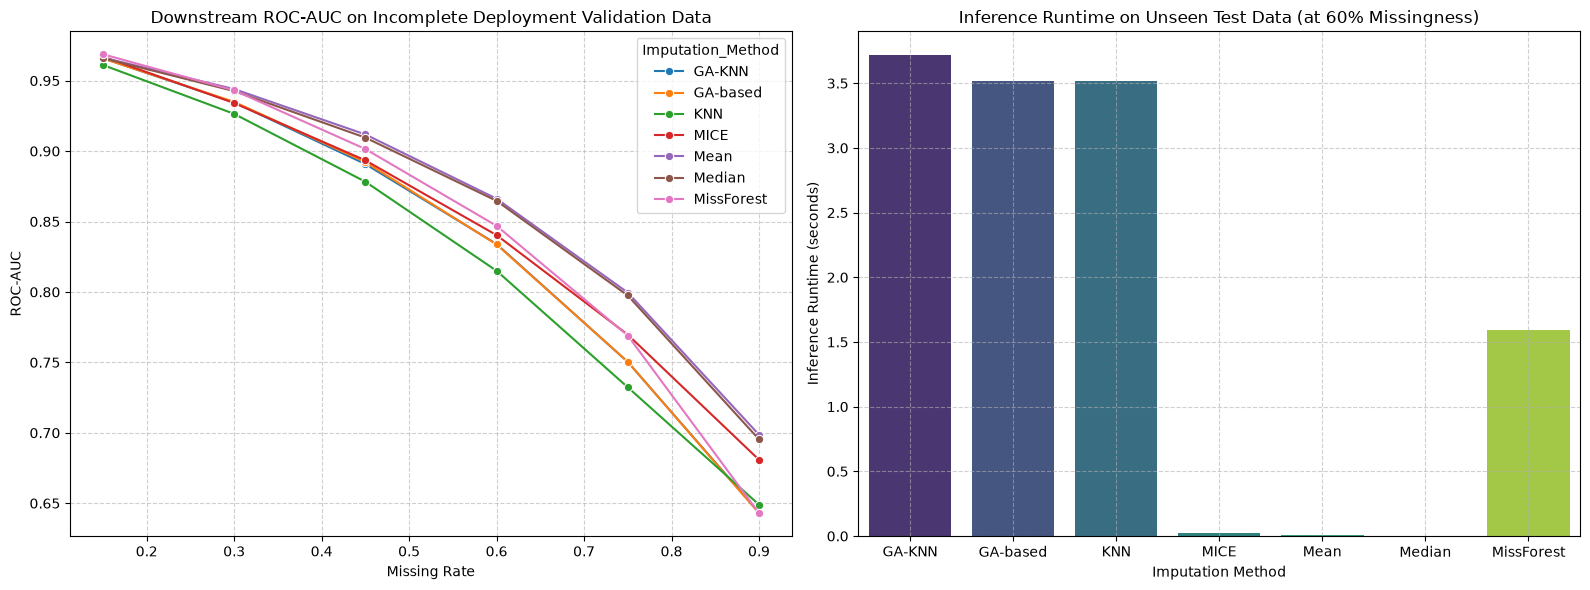

In [10]:
# ==============================================================================
# VISUALISASI HASIL NESTED CV: CLEAN VS INCOMPLETE OUTER_VAL
# ==============================================================================
summary_plot = (
    results_df.groupby(["Missing_Rate", "Imputation_Method"])[
        ["Clean_Val_ROC_AUC", "Incomp_Val_ROC_AUC", "Train_Impute_Runtime", "Inference_Runtime"]
    ]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: ROC-AUC on Incomplete outer_val
sns.lineplot(
    data=summary_plot,
    x="Missing_Rate",
    y="Incomp_Val_ROC_AUC",
    hue="Imputation_Method",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Downstream ROC-AUC on Incomplete Deployment Validation Data")
axes[0].set_xlabel("Missing Rate")
axes[0].set_ylabel("ROC-AUC")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot 2: Imputation vs Inference Runtime
sns.barplot(
    data=summary_plot[summary_plot["Missing_Rate"] == 0.60],
    x="Imputation_Method",
    y="Inference_Runtime",
    palette="viridis",
    ax=axes[1]
)
axes[1].set_title("Inference Runtime on Unseen Test Data (at 60% Missingness)")
axes[1].set_xlabel("Imputation Method")
axes[1].set_ylabel("Inference Runtime (seconds)")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("ga_nested_cv_plot_p1_9.png", dpi=300)
plt.show()


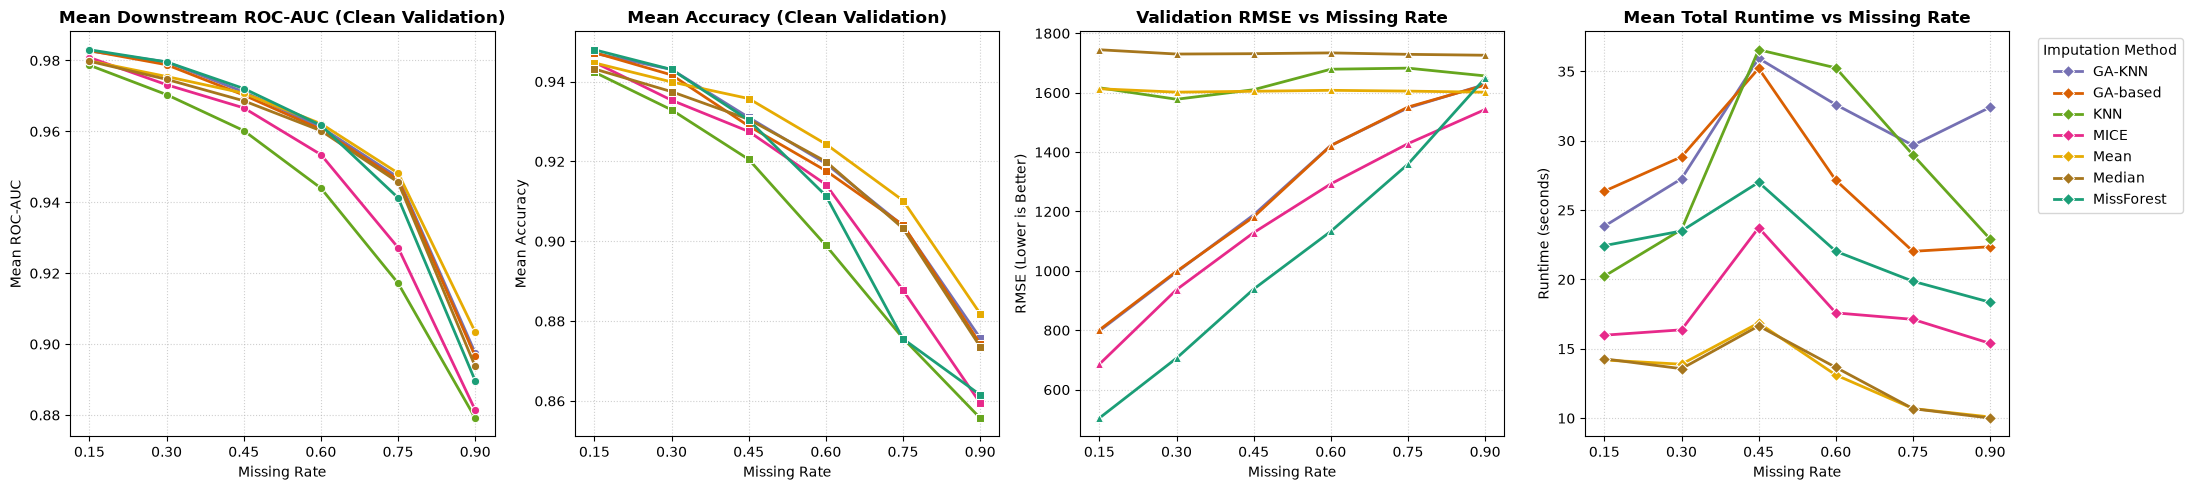

[V] Grafik Clean Validation tersimpan ke: evaluasi_metrik_clean_val.png


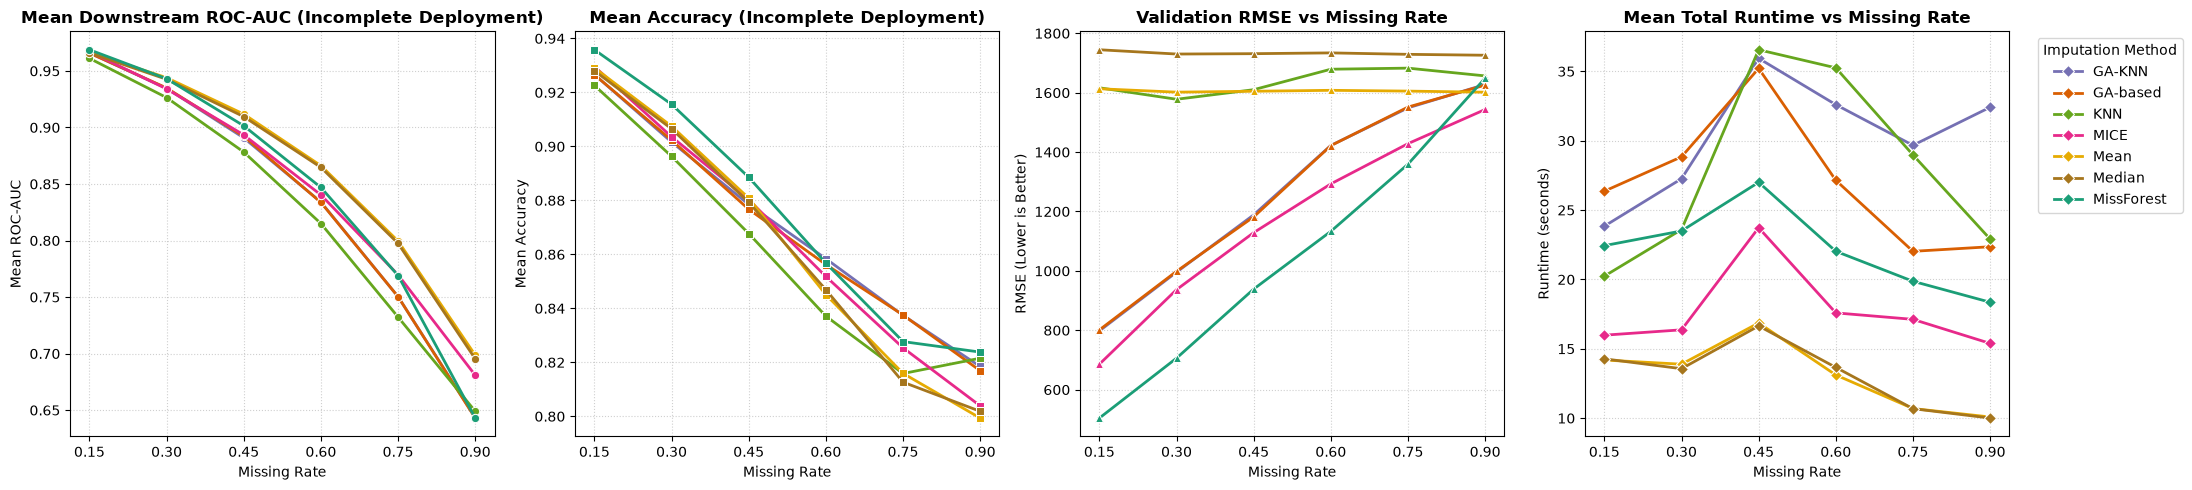

[V] Grafik Incomplete Deployment tersimpan ke: evaluasi_metrik_incomp_val.png


In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==============================================================================
# 1. KONFIGURASI FILE & PALET WARNA
# ==============================================================================
CSV_INPUT_PATH = "ga_nested_cv_results_p1_9.csv"  # Sesuaikan dengan nama file CSV Anda
PLOT_CLEAN_OUTPUT = "evaluasi_metrik_clean_val.png"
PLOT_INCOMP_OUTPUT = "evaluasi_metrik_incomp_val.png"

colors = {
    "GA-based": "#d95f02",
    "GA-KNN": "#7570b3",
    "MissForest": "#1b9e77",
    "MICE": "#e7298a",
    "KNN": "#66a61e",
    "Mean": "#e6ab02",
    "Median": "#a6761d",
}

# Baca data
results_df = pd.read_csv(CSV_INPUT_PATH)
missing_rates = sorted(results_df["Missing_Rate"].unique())

# ==============================================================================
# 2. AGREGASI DATA (Mean lintas Seed, Fold, & Tuning Method)
# ==============================================================================
metric_cols = [
    "Clean_Val_ROC_AUC",
    "Clean_Val_Accuracy",
    "Incomp_Val_ROC_AUC",
    "Incomp_Val_Accuracy",
    "Val_RMSE",
    "Total_Runtime",
]

agg_df = (
    results_df.groupby(["Missing_Rate", "Imputation_Method"])[metric_cols]
    .mean()
    .reset_index()
)


# ==============================================================================
# 3. FUNGSI GENERATOR PLOT (4 Subplot)
# ==============================================================================
def generate_evaluation_plot(
    df, auc_col, acc_col, rmse_col, runtime_col, mode_title, output_filename
):
  fig, axes = plt.subplots(1, 4, figsize=(22, 5))

  # Subplot 1: ROC-AUC
  sns.lineplot(
      data=df,
      x="Missing_Rate",
      y=auc_col,
      hue="Imputation_Method",
      palette=colors,
      marker="o",
      linewidth=2,
      ax=axes[0],
  )
  axes[0].set_title(
      f"Mean Downstream ROC-AUC ({mode_title})", fontweight="bold"
  )
  axes[0].set_xlabel("Missing Rate")
  axes[0].set_ylabel("Mean ROC-AUC")
  axes[0].set_xticks(missing_rates)
  axes[0].grid(True, linestyle=":", alpha=0.6)
  axes[0].get_legend().remove()

  # Subplot 2: Accuracy
  sns.lineplot(
      data=df,
      x="Missing_Rate",
      y=acc_col,
      hue="Imputation_Method",
      palette=colors,
      marker="s",
      linewidth=2,
      ax=axes[1],
  )
  axes[1].set_title(f"Mean Accuracy ({mode_title})", fontweight="bold")
  axes[1].set_xlabel("Missing Rate")
  axes[1].set_ylabel("Mean Accuracy")
  axes[1].set_xticks(missing_rates)
  axes[1].grid(True, linestyle=":", alpha=0.6)
  axes[1].get_legend().remove()

  # Subplot 3: Imputation RMSE
  sns.lineplot(
      data=df,
      x="Missing_Rate",
      y=rmse_col,
      hue="Imputation_Method",
      palette=colors,
      marker="^",
      linewidth=2,
      ax=axes[2],
  )
  axes[2].set_title("Validation RMSE vs Missing Rate", fontweight="bold")
  axes[2].set_xlabel("Missing Rate")
  axes[2].set_ylabel("RMSE (Lower is Better)")
  axes[2].set_xticks(missing_rates)
  axes[2].grid(True, linestyle=":", alpha=0.6)
  axes[2].get_legend().remove()

  # Subplot 4: Total Runtime
  sns.lineplot(
      data=df,
      x="Missing_Rate",
      y=runtime_col,
      hue="Imputation_Method",
      palette=colors,
      marker="D",
      linewidth=2,
      ax=axes[3],
  )
  axes[3].set_title("Mean Total Runtime vs Missing Rate", fontweight="bold")
  axes[3].set_xlabel("Missing Rate")
  axes[3].set_ylabel("Runtime (seconds)")
  axes[3].set_xticks(missing_rates)
  axes[3].grid(True, linestyle=":", alpha=0.6)

  # Legenda global di sisi kanan
  axes[3].legend(
      title="Imputation Method",
      bbox_to_anchor=(1.05, 1),
      loc="upper left",
      frameon=True,
  )

  plt.tight_layout()
  plt.savefig(output_filename, dpi=300, bbox_inches="tight")
  plt.show()
  print(f"[V] Grafik {mode_title} tersimpan ke: {output_filename}")


# ==============================================================================
# 4. EKSEKUSI PEMBUATAN KEDUA GRAFIK
# ==============================================================================

# 1. Grafik Kondisi Clean Validation (0% Missing pada Data Uji)
generate_evaluation_plot(
    df=agg_df,
    auc_col="Clean_Val_ROC_AUC",
    acc_col="Clean_Val_Accuracy",
    rmse_col="Val_RMSE",
    runtime_col="Total_Runtime",
    mode_title="Clean Validation",
    output_filename=PLOT_CLEAN_OUTPUT,
)

# 2. Grafik Kondisi Incomplete Validation (Out-of-Sample Missingness / Real Deployment)
generate_evaluation_plot(
    df=agg_df,
    auc_col="Incomp_Val_ROC_AUC",
    acc_col="Incomp_Val_Accuracy",
    rmse_col="Val_RMSE",
    runtime_col="Total_Runtime",
    mode_title="Incomplete Deployment",
    output_filename=PLOT_INCOMP_OUTPUT,
)

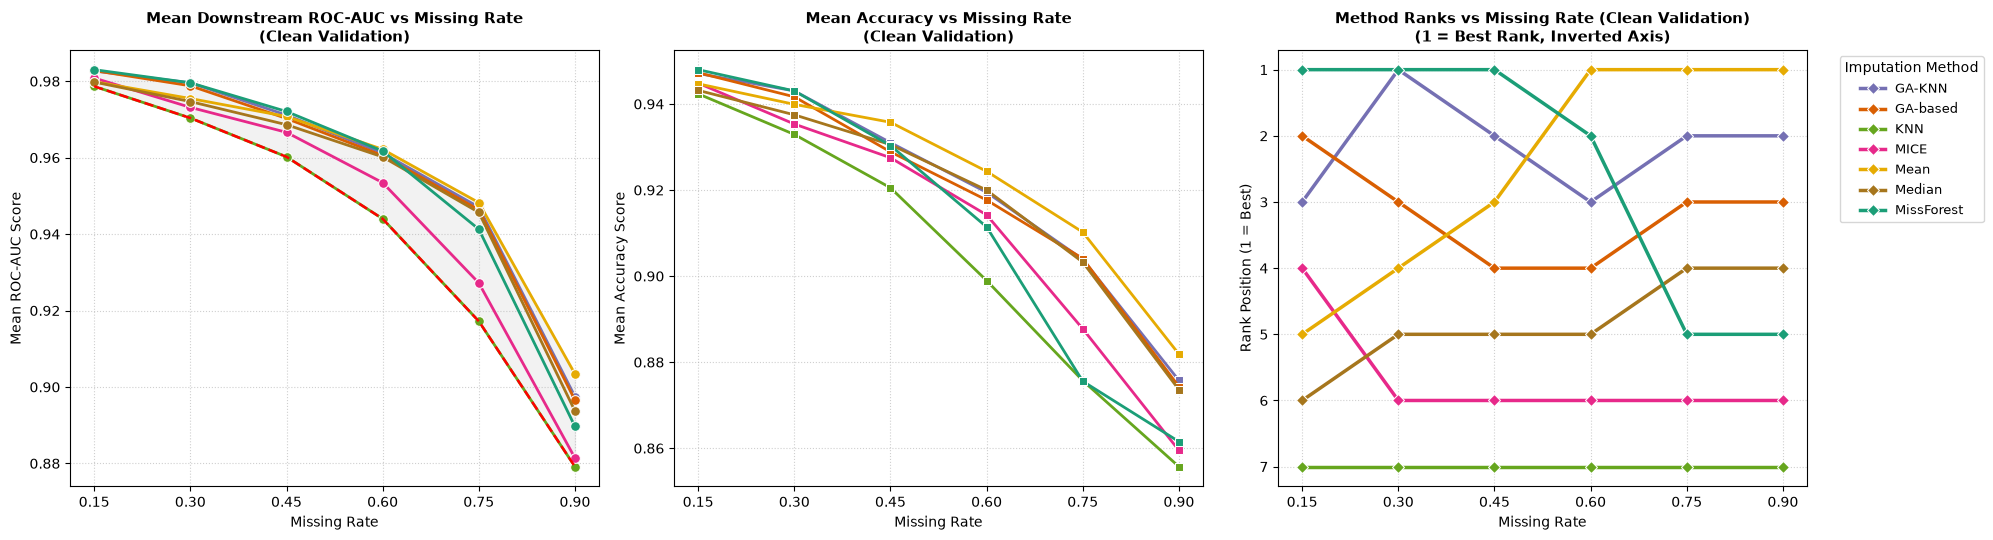

[V] Grafik 3-Panel (Clean Validation) berhasil disimpan ke: ga_nested_cv_3panel_clean.png


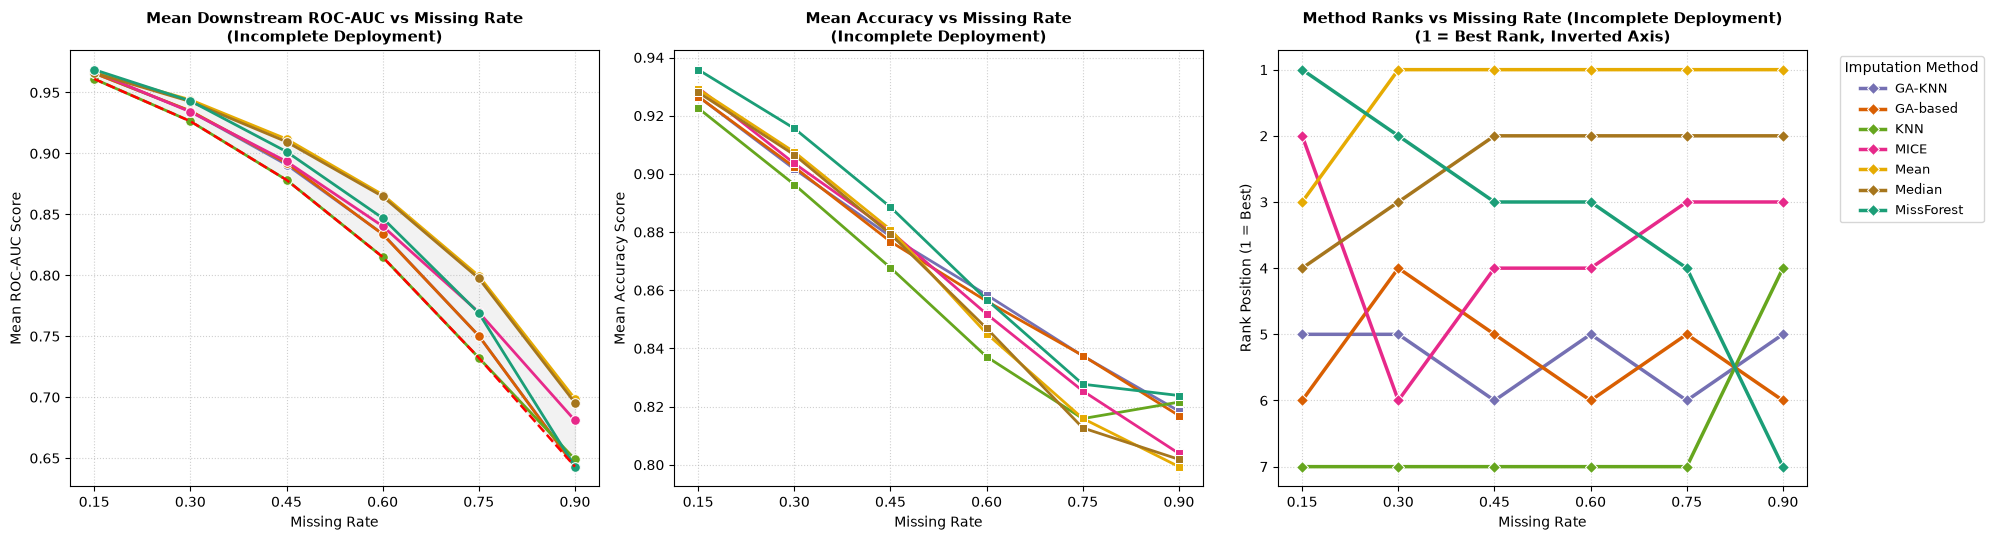

[V] Grafik 3-Panel (Incomplete Deployment) berhasil disimpan ke: ga_nested_cv_3panel_incomp.png


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==============================================================================
# 1. KONFIGURASI FILE & PALET WARNA
# ==============================================================================
CSV_INPUT_PATH = "ga_nested_cv_results_p1_9.csv"
OUTPUT_CLEAN_PLOT = "ga_nested_cv_3panel_clean.png"
OUTPUT_INCOMP_PLOT = "ga_nested_cv_3panel_incomp.png"

colors = {
    "GA-based": "#d95f02",
    "GA-KNN": "#7570b3",
    "MissForest": "#1b9e77",
    "MICE": "#e7298a",
    "KNN": "#66a61e",
    "Mean": "#e6ab02",
    "Median": "#a6761d",
}

# Load data
results_df = pd.read_csv(CSV_INPUT_PATH)
missing_ticks = sorted(results_df["Missing_Rate"].unique())


# ==============================================================================
# 2. FUNGSI PEMBUAT GRAFIK 3-PANEL (ROC-AUC, Accuracy, & Method Rank)
# ==============================================================================
def generate_3panel_plot(df, auc_col, acc_col, mode_title, output_filename):
  # Agregasi rata-rata per Missing_Rate dan Imputation_Method lintas Seed, Fold, & Tuning Method
  summary = (
      df.groupby(["Missing_Rate", "Imputation_Method"])[[auc_col, acc_col]]
      .mean()
      .reset_index()
  )

  # Hitung Peringkat Metode berdasarkan rata-rata ROC-AUC (1 = Terbaik, 7 = Terburuk)
  summary["ROC_Rank"] = summary.groupby("Missing_Rate")[auc_col].rank(
      ascending=False, method="min"
  )

  fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

  # --- Panel 1: Rata-rata Downstream ROC-AUC vs Missing Rate ---
  ax1 = axes[0]
  sns.lineplot(
      data=summary,
      x="Missing_Rate",
      y=auc_col,
      hue="Imputation_Method",
      palette=colors,
      marker="o",
      markersize=7,
      linewidth=2,
      ax=ax1,
  )

  # Batas Performa (Worst vs Best Bound)
  worst_perf = summary.groupby("Missing_Rate")[auc_col].min().reset_index()
  best_perf = summary.groupby("Missing_Rate")[auc_col].max().values

  ax1.plot(
      worst_perf["Missing_Rate"],
      worst_perf[auc_col],
      color="red",
      linestyle="--",
      linewidth=1.8,
      label="Worst Baseline Bound",
  )
  ax1.fill_between(
      worst_perf["Missing_Rate"],
      worst_perf[auc_col],
      best_perf,
      color="grey",
      alpha=0.1,
      label="Performance Band",
  )

  ax1.set_title(
      f"Mean Downstream ROC-AUC vs Missing Rate\n({mode_title})",
      fontsize=11,
      fontweight="bold",
  )
  ax1.set_xlabel("Missing Rate", fontsize=10)
  ax1.set_ylabel("Mean ROC-AUC Score", fontsize=10)
  ax1.set_xticks(missing_ticks)
  ax1.grid(True, linestyle=":", alpha=0.6)
  ax1.get_legend().remove()

  # --- Panel 2: Rata-rata Accuracy vs Missing Rate ---
  ax2 = axes[1]
  sns.lineplot(
      data=summary,
      x="Missing_Rate",
      y=acc_col,
      hue="Imputation_Method",
      palette=colors,
      marker="s",
      markersize=6,
      linewidth=2,
      ax=ax2,
  )

  ax2.set_title(
      f"Mean Accuracy vs Missing Rate\n({mode_title})",
      fontsize=11,
      fontweight="bold",
  )
  ax2.set_xlabel("Missing Rate", fontsize=10)
  ax2.set_ylabel("Mean Accuracy Score", fontsize=10)
  ax2.set_xticks(missing_ticks)
  ax2.grid(True, linestyle=":", alpha=0.6)
  ax2.get_legend().remove()

  # --- Panel 3: Peringkat Metode vs Missing Rate (1 = Terbaik, 7 = Terburuk) ---
  ax3 = axes[2]
  sns.lineplot(
      data=summary,
      x="Missing_Rate",
      y="ROC_Rank",
      hue="Imputation_Method",
      palette=colors,
      marker="D",
      markersize=6,
      linewidth=2.5,
      ax=ax3,
  )

  ax3.set_title(
      f"Method Ranks vs Missing Rate ({mode_title})\n(1 = Best Rank, Inverted"
      " Axis)",
      fontsize=11,
      fontweight="bold",
  )
  ax3.set_xlabel("Missing Rate", fontsize=10)
  ax3.set_ylabel("Rank Position (1 = Best)", fontsize=10)
  ax3.set_yticks(range(1, 8))
  ax3.set_xticks(missing_ticks)
  ax3.invert_yaxis()  # Peringkat 1 di paling atas
  ax3.grid(True, linestyle=":", alpha=0.6)

  # Legenda tunggal di sebelah kanan Panel 3
  ax3.legend(
      title="Imputation Method",
      bbox_to_anchor=(1.05, 1),
      loc="upper left",
      frameon=True,
      fontsize=9,
  )

  plt.tight_layout()
  plt.savefig(output_filename, dpi=300, bbox_inches="tight")
  plt.show()
  print(f"[V] Grafik 3-Panel ({mode_title}) berhasil disimpan ke: {output_filename}")


# ==============================================================================
# 3. EKSEKUSI PENYIMPANAN KEDUA GRAFIK
# ==============================================================================

# 1. Mode Clean Validation (Data Uji 0% Missing)
generate_3panel_plot(
    df=results_df,
    auc_col="Clean_Val_ROC_AUC",
    acc_col="Clean_Val_Accuracy",
    mode_title="Clean Validation",
    output_filename=OUTPUT_CLEAN_PLOT,
)

# 2. Mode Incomplete Deployment (Data Uji Baru Mengandung Missing)
generate_3panel_plot(
    df=results_df,
    auc_col="Incomp_Val_ROC_AUC",
    acc_col="Incomp_Val_Accuracy",
    mode_title="Incomplete Deployment",
    output_filename=OUTPUT_INCOMP_PLOT,
)